In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [12]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.astype(int)

print("Dataset Shape:", df.shape)
print(df["target"].value_counts())

Dataset Shape: (302, 14)
target
1    164
0    138
Name: count, dtype: int64


In [13]:
def split_data(X, y, test_size=0.2, seed=42):

    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)

        split = int(len(idx) * (1 - test_size))
        train_idx.extend(idx[:split])
        test_idx.extend(idx[split:])

    return (X[train_idx], X[test_idx],
            y[train_idx], y[test_idx])


X_train, X_test, y_train, y_test = split_data(X, y)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (241, 13)
Testing: (61, 13)


In [14]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

In [15]:
def sigmoid(z):
    z = np.clip(z, -20, 20)
    return 1 / (1 + np.exp(-z))


def train_logistic(X, y, learning_rate=0.01, epochs=1000):

    weights = np.zeros(X.shape[1])
    bias = 0

    for _ in range(epochs):

        predictions = sigmoid(X @ weights + bias)

        dw = X.T @ (predictions - y) / len(y)
        db = np.mean(predictions - y)

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias


weights, bias = train_logistic(X_train_scaled, y_train)

logistic_scores = sigmoid(X_test_scaled @ weights + bias)

print("Logistic Regression probabilities:")
print(logistic_scores[:10])

Logistic Regression probabilities:
[0.20922938 0.15988305 0.01064521 0.24679254 0.00704361 0.70213277
 0.01364852 0.00622556 0.01703299 0.09345793]


In [16]:
def gini(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1 - np.sum(p ** 2)


def build_tree(X, y, depth=0, max_depth=6):

    classes, counts = np.unique(y, return_counts=True)
    prediction = np.mean(y)

    if len(classes) == 1 or depth >= max_depth or len(y) < 4:
        return prediction

    features = np.random.choice(
        X.shape[1], max(1, int(np.sqrt(X.shape[1]))), replace=False
    )

    best_gain, best_feature, best_threshold = 0, None, None

    for feature in features:
        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:
            left = X[:, feature] <= threshold
            right = ~left

            if not left.any() or not right.any():
                continue

            weighted = (
                left.sum() * gini(y[left]) +
                right.sum() * gini(y[right])
            ) / len(y)

            gain = gini(y) - weighted

            if gain > best_gain:
                best_gain, best_feature, best_threshold = gain, feature, threshold

    if best_feature is None:
        return prediction

    left = X[:, best_feature] <= best_threshold

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_tree(X[left], y[left], depth + 1, max_depth),
        "right": build_tree(X[~left], y[~left], depth + 1, max_depth)
    }


def predict_tree(tree, row):

    while isinstance(tree, dict):
        tree = tree["left"] if row[tree["feature"]] <= tree["threshold"] else tree["right"]

    return tree


def train_forest(X, y, n_trees=25):

    np.random.seed(42)
    forest = []

    for _ in range(n_trees):
        idx = np.random.choice(len(X), len(X), replace=True)
        forest.append(build_tree(X[idx], y[idx]))

    return forest


forest = train_forest(X_train, y_train)


def forest_scores(forest, X):

    return np.array([
        np.mean([predict_tree(tree, row) for tree in forest])
        for row in X
    ])


rf_scores = forest_scores(forest, X_test)

print("Random Forest scores:")
print(rf_scores[:10])

Random Forest scores:
[0.10840284 0.49688799 0.         0.24865834 0.08666667 0.74081595
 0.         0.13166667 0.104      0.16912121]


In [17]:
def build_boost_tree(X, grad, hess, depth=0, max_depth=2, reg=1):

    G, H = np.sum(grad), np.sum(hess)
    leaf = -G / (H + reg)

    if depth >= max_depth or len(X) < 2:
        return leaf

    best_gain, best_feature, best_threshold = 0, None, None

    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:
            left = X[:, feature] <= threshold
            right = ~left

            if not left.any() or not right.any():
                continue

            GL, HL = np.sum(grad[left]), np.sum(hess[left])
            GR, HR = np.sum(grad[right]), np.sum(hess[right])

            gain = 0.5 * (
                GL**2 / (HL + reg) +
                GR**2 / (HR + reg) -
                G**2 / (H + reg)
            )

            if gain > best_gain:
                best_gain, best_feature, best_threshold = gain, feature, threshold

    if best_feature is None:
        return leaf

    left = X[:, best_feature] <= best_threshold

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_boost_tree(
            X[left], grad[left], hess[left], depth + 1, max_depth, reg
        ),
        "right": build_boost_tree(
            X[~left], grad[~left], hess[~left], depth + 1, max_depth, reg
        )
    }


def train_boosting(X, y, n_estimators=30, lr=0.1):

    p = np.clip(np.mean(y), 1e-5, 1 - 1e-5)
    base = np.log(p / (1 - p))
    predictions = np.full(len(y), base)
    trees = []

    for _ in range(n_estimators):

        probability = sigmoid(predictions)
        grad = probability - y
        hess = probability * (1 - probability)

        tree = build_boost_tree(X, grad, hess)
        trees.append(tree)

        updates = np.array([predict_tree(tree, row) for row in X])
        predictions += lr * updates

    return base, trees


base, boost_trees = train_boosting(X_train, y_train)


def boosting_scores(X, base, trees, lr=0.1):

    predictions = np.full(len(X), base)

    for tree in trees:
        predictions += lr * np.array([
            predict_tree(tree, row) for row in X
        ])

    return sigmoid(predictions)


boost_scores = boosting_scores(X_test, base, boost_trees)

print("Gradient Boosting scores:")
print(boost_scores[:10])

Gradient Boosting scores:
[0.13299615 0.54170485 0.0562917  0.2280037  0.0757063  0.69382445
 0.0528183  0.0528183  0.15682159 0.0997773 ]


In [18]:
def calculate_roc(y_true, scores):

    thresholds = np.linspace(1, 0, 101)

    tpr_values = []
    fpr_values = []

    for threshold in thresholds:

        predictions = (scores >= threshold).astype(int)

        tp = np.sum((y_true == 1) & (predictions == 1))
        fn = np.sum((y_true == 1) & (predictions == 0))
        fp = np.sum((y_true == 0) & (predictions == 1))
        tn = np.sum((y_true == 0) & (predictions == 0))

        tpr = tp / (tp + fn) if tp + fn else 0
        fpr = fp / (fp + tn) if fp + tn else 0

        tpr_values.append(tpr)
        fpr_values.append(fpr)

    return np.array(fpr_values), np.array(tpr_values)


log_fpr, log_tpr = calculate_roc(y_test, logistic_scores)
rf_fpr, rf_tpr = calculate_roc(y_test, rf_scores)
boost_fpr, boost_tpr = calculate_roc(y_test, boost_scores)

In [19]:
def calculate_auc(fpr, tpr):

    order = np.argsort(fpr)
    fpr = fpr[order]
    tpr = tpr[order]

    auc = 0

    for i in range(1, len(fpr)):

        width = fpr[i] - fpr[i - 1]
        height = (tpr[i] + tpr[i - 1]) / 2

        auc += width * height

    return auc


log_auc = calculate_auc(log_fpr, log_tpr)
rf_auc = calculate_auc(rf_fpr, rf_tpr)
boost_auc = calculate_auc(boost_fpr, boost_tpr)

print("Logistic Regression AUC:", round(log_auc, 4))
print("Random Forest AUC:", round(rf_auc, 4))
print("Gradient Boosting AUC:", round(boost_auc, 4))

Logistic Regression AUC: 0.901
Random Forest AUC: 0.9237
Gradient Boosting AUC: 0.9161


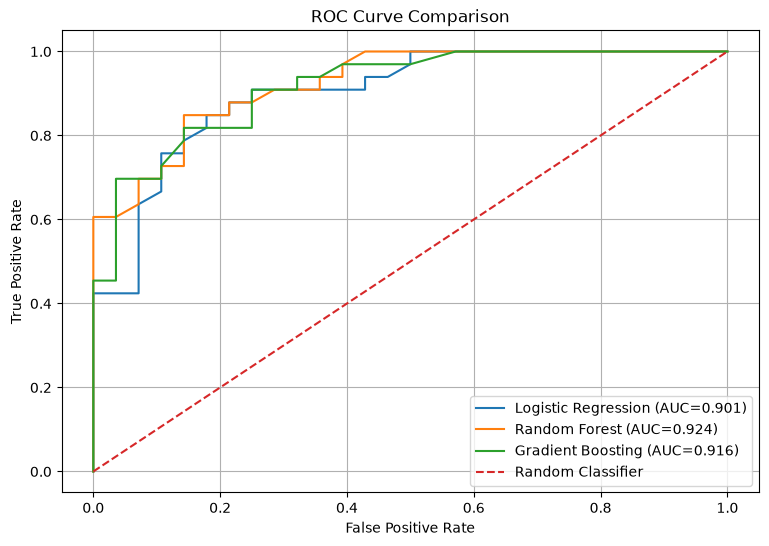

In [20]:
plt.figure(figsize=(9, 6))

plt.plot(log_fpr, log_tpr, label=f"Logistic Regression (AUC={log_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC={rf_auc:.3f})")
plt.plot(boost_fpr, boost_tpr, label=f"Gradient Boosting (AUC={boost_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

,Model,AUC Score
1,Random Forest,0.923701
2,Gradient Boosting,0.916126
0,Logistic Regression,0.900974


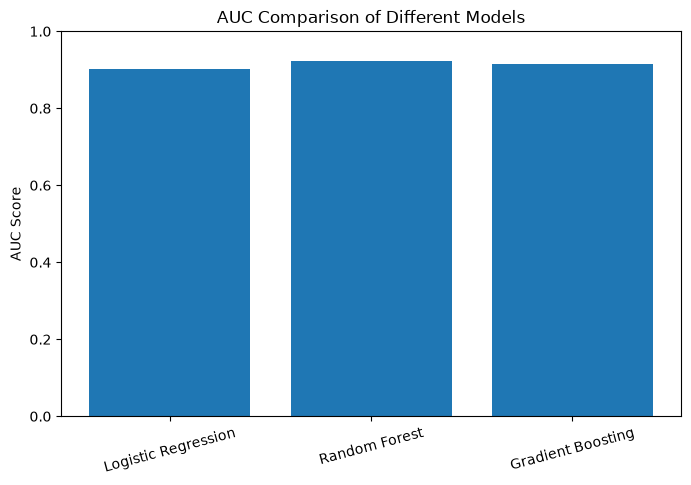

In [21]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "AUC Score": [log_auc, rf_auc, boost_auc]
})

display(comparison.sort_values("AUC Score", ascending=False))

plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["AUC Score"])
plt.title("AUC Comparison of Different Models")
plt.ylabel("AUC Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

## Conclusion

In this task, ROC curves and AUC scores were calculated manually for
Logistic Regression, Random Forest, and Gradient Boosting models.

True Positive Rate (TPR) and False Positive Rate (FPR) were calculated
at multiple classification thresholds.

ROC curves were plotted using Matplotlib, and AUC scores were calculated
using the trapezoidal rule without built-in ROC or AUC functions.

The model with the higher AUC score demonstrates better ability to
distinguish between positive and negative classes on the test dataset.